# 08 — XGBoost: train, tune and interpret

Run after Notebooks 01–05, using **Restart Kernel and Run All** in the project kernel. This is one of the four classifier notebooks (06–09). Each loads the same prepared folds; no earlier model must be trained first. Missing folds are prepared safely through `prepare.py`, without any combined model-training notebook.

The declared 16-trial search, references, metrics and report notes below are retained from the completed Optuna study. Every trial uses all three expanding 2025 folds. Mean fold average precision (AP) selects the configuration; the earliest trial breaks ties. The selected candidate is fitted through December 2025; January–March 2026 validation selects its F1 cutoff. These periods have already been inspected, so this remains exploratory/reproduction work. No test rows or registered November outcomes are read.

Each execution saves a new `08_xgboost/<timestamp>/` folder inside the active data run. Nothing replaces an existing dashboard model. Run **10_model_comparison.ipynb** after all four model notebooks to compare matching results without refitting. Section 1 explains the technique, sections 4–6 show results, and section 7 supports report writing.


## 1. Settings and technique

XGBoost builds trees sequentially, using each new tree to improve the current objective. Learning rate controls the contribution of each tree; regularisation and child-support constraints restrict complexity. Numerical features are median-imputed with missing indicators; categories are one-hot encoded. No numerical scaling is needed. Each fit learns preprocessing from its training fold only.

| Hyperparameter | Search options | Purpose |
|---|---|---|
| `max_depth` | 3, 5, 7 | Limit tree complexity. |
| `min_child_weight` | 1, 5, 10 | Require a minimum sum of instance Hessians in a child, not a fixed row count. |
| `reg_lambda` | 1, 5, 10 | L2 regularisation on leaf weights. |
| `weighting` | `"none"`, `"balanced"` | Set `scale_pos_weight` to 1 or training negatives / training positives. |

`weighting` is a notebook search option, not an XGBoost constructor parameter. Its numeric `scale_pos_weight` is recalculated using each fit's training labels only; no validation labels enter that calculation. Weighted scores remain uncalibrated.

The first two trials reproduce Notebook 06's depth-3/depth-5 settings: child weight 1, L2 regularisation 1 and training-ratio positive weighting. The next two remove that weighting. Keeping boosting rounds and learning rate fixed limits the search; this study does not optimise every XGBoost parameter.

In [1]:
import sys
from pathlib import Path
REPOSITORY_ROOT = Path.cwd()
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    raise FileNotFoundError("Open the FYP project folder before running this notebook.")
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

import hashlib
import json
from datetime import datetime, timezone
from importlib import metadata, reload
from time import perf_counter
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import optuna
except ModuleNotFoundError:
    raise ModuleNotFoundError("Install Optuna in this kernel: %pip install 'optuna>=4,<5', then restart and Run All.") from None
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
try:
    import xgboost as xgb
    from xgboost import XGBClassifier
except ModuleNotFoundError:
    raise ModuleNotFoundError("XGBoost is missing in this kernel. Install the repository requirements, then restart and Run All.") from None
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import pricecatcher_config as cfg
cfg = reload(cfg)

SEED = 42
N_TRIALS = 16
TREES = 150
N_JOBS = 2
SEARCH_SPACE = {
    "max_depth": [3, 5, 7],
    "min_child_weight": [1, 5, 10],
    "reg_lambda": [1.0, 5.0, 10.0],
    "weighting": ["none", "balanced"],
}
REFERENCE_SETTINGS = [
    ("Reference depth=3", {"max_depth": 3, "min_child_weight": 1,
                           "reg_lambda": 1.0, "weighting": "balanced"}),
    ("Reference depth=5", {"max_depth": 5, "min_child_weight": 1,
                           "reg_lambda": 1.0, "weighting": "balanced"}),
    ("Unweighted depth=3", {"max_depth": 3, "min_child_weight": 1,
                            "reg_lambda": 1.0, "weighting": "none"}),
    ("Unweighted depth=5", {"max_depth": 5, "min_child_weight": 1,
                            "reg_lambda": 1.0, "weighting": "none"}),
]
FOLDS = ["fold_1", "fold_2", "fold_3"]
print("Python:", sys.executable)
print("Prepared run:", cfg.PROJECT_ROOT)
print("XGBoost:", xgb.__version__)
print("Trials:", N_TRIALS, "| Folds:", len(FOLDS), "| Trees:", TREES, "| Fixed target: 10%")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /usr/local/bin/python3.12
Prepared run: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240
XGBoost: 3.4.1
Trials: 16 | Folds: 3 | Trees: 150 | Fixed target: 10%


## 2. Continue the preparation from Notebook 05

The holdout train/validation inputs must already exist. They are never regenerated here. Existing complete expanding folds are reused. If a fold is absent, the existing `prepare.py` runs only preparation notebooks for that fold, using the verified local source; it does not train the old comparison models.

Partial fold inputs and missing inputs belonging to saved experiments stop execution rather than being overwritten. Restore a matching completed snapshot or start a deliberate new preparation from 01 if needed. The helper still applies item eligibility and cleaning rules using each fold's training period. This avoids deriving early-fold filters from all of 2025.

In [2]:
def file_hash(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

folders = {name: cfg.PROJECT_ROOT / "experiments" / name / "05_modelling"
           for name in FOLDS + ["holdout"]}
input_paths = [folder / filename for folder in folders.values()
               for filename in ["experiment_settings.json", "train.parquet", "validation.parquet"]]
# A manual Run All in 01–05 normally prepares holdout only.
required_names = ["experiment_settings.json", "train.parquet", "validation.parquet"]
holdout_missing = [str(folders["holdout"] / name) for name in required_names
                   if not (folders["holdout"] / name).is_file()]
if holdout_missing:
    raise FileNotFoundError("Complete Notebook 05 first. Missing: " + ", ".join(holdout_missing))
holdout_hashes = {name: file_hash(folders["holdout"] / name) for name in required_names}
missing_folds = [name for name in FOLDS
                 if not all((folders[name] / filename).is_file() for filename in required_names)]
if missing_folds:
    partial_folds = [name for name in missing_folds
                     if folders[name].exists() and any(folders[name].iterdir())]
    saved_models = any((folder / "best_model.joblib").exists() for folder in cfg.MODEL_DIRS)
    saved_studies = (any(cfg.PROJECT_ROOT.glob("*_optuna/*/study_manifest.json"))
                     or any(cfg.PROJECT_ROOT.glob("0[6-9]_*/*/study_manifest.json")))
    if partial_folds or saved_models or saved_studies:
        raise FileNotFoundError(
            f"Incomplete folds: {missing_folds}. Restore their matching prepared inputs; "
            "partial inputs or saved experiments are present. To reproduce from source, start a separate run with 01–05.")
    if not (REPOSITORY_ROOT / "prepare.py").is_file():
        raise FileNotFoundError("Keep prepare.py beside this notebook; it prepares missing chronological folds.")
    cfg.verify_source_snapshot()
    import os
    import subprocess
    for name in missing_folds:
        print("Preparing chronological inputs (no model training):", name, flush=True)
        subprocess.run([sys.executable, str(REPOSITORY_ROOT / "prepare.py"), "--experiment", name],
                       cwd=REPOSITORY_ROOT,
                       env={**os.environ, "PRICECATCHER_DATA_DIR": str(cfg.PROJECT_ROOT)}, check=True)
if any(file_hash(folders["holdout"] / name) != digest for name, digest in holdout_hashes.items()):
    raise ValueError("Holdout preparation changed during fold preparation. Stop and restore the matching snapshot.")
missing = [str(path) for path in input_paths if not path.is_file()]
if missing:
    raise FileNotFoundError("Preparation did not produce the required files: " + ", ".join(missing))
input_hashes = {str(path.relative_to(cfg.PROJECT_ROOT)): file_hash(path) for path in input_paths}
settings_by_fold = {name: json.loads((folder / "experiment_settings.json").read_text())
                    for name, folder in folders.items()}
settings = settings_by_fold["holdout"]
FEATURES = settings["feature_columns"]
NUMERIC = settings["numeric_features"]
CATEGORICAL = settings["categorical_features"]
if len(FEATURES) != len(set(FEATURES)) or sorted(NUMERIC + CATEGORICAL) != sorted(FEATURES):
    raise ValueError("Numeric and categorical features must partition the feature list.")
if any(c.startswith("next_") or c in ["surge_label", "split"] for c in FEATURES):
    raise ValueError("Future outcomes must not enter the model features.")
if settings["surge_threshold_pct"] != 10:
    raise ValueError("This study requires the existing fixed 10% target.")
variable = {"experiment", "train_end", "validation_end", "test_end", "evaluation_end",
            "apply_documented_exclusions", "source_manifest_sha256", "source_snapshot_sha256"}
policy = {k: v for k, v in settings["preparation"].items() if k not in variable}
source_key = ("source_snapshot_sha256" if settings["preparation"].get("source_snapshot_sha256")
              else "source_manifest_sha256")
source_id = settings["preparation"].get(source_key)
if not source_id:
    raise ValueError("Source identity is missing; restore matching preparation metadata.")

frames = {}
for name, folder in folders.items():
    s = settings_by_fold[name]
    if tuple(s[k] for k in ["train_end", "validation_end", "test_end"]) != tuple(cfg.EXPERIMENTS[name]):
        raise ValueError(f"{name}: date settings differ from the configured chronological experiment.")
    for key in ["feature_columns", "numeric_features", "categorical_features", "target_status", "surge_threshold_pct"]:
        if s[key] != settings[key]:
            raise ValueError(f"{name}: incompatible {key}.")
    if ({k: v for k, v in s["preparation"].items() if k not in variable} != policy
            or s["preparation"].get(source_key) != source_id
            or s["preparation"].get("experiment") != name):
        raise ValueError(f"{name}: shared source/policies differ. Restore consistent prepared inputs.")
    if name in FOLDS and s["preparation"].get("apply_documented_exclusions"):
        raise ValueError("Early folds must retain retrospective exceptions whose review dates are unknown.")
    frames[name] = {}
    for split in ["train", "validation"]:
        frame = pd.read_parquet(folder / f"{split}.parquet")
        required = FEATURES + ["surge_label", "week_start", "next_week_end", "project_group"]
        if frame.empty or set(required) - set(frame.columns):
            raise ValueError(f"{name}/{split}: empty or incomplete input.")
        if frame.surge_label.isna().any() or not frame.surge_label.isin([0, 1]).all() or frame.surge_label.nunique() != 2:
            raise ValueError(f"{name}/{split}: overall evaluation requires both observed classes.")
        for col in ["week_start", "next_week_end"]:
            frame[col] = pd.to_datetime(frame[col])
        if (frame[["week_start", "next_week_end"]].isna().any().any()
                or not frame.week_start.dt.dayofweek.eq(0).all()
                or not frame.next_week_end.eq(frame.week_start + pd.Timedelta(days=13)).all()):
            raise ValueError(f"{name}/{split}: invalid calendar-week horizons.")
        upper = pd.Timestamp(s["train_end" if split == "train" else "validation_end"])
        if not frame.next_week_end.le(upper).all():
            raise ValueError(f"{name}/{split}: outcome crosses its time boundary.")
        if split == "validation" and not (frame.week_start + pd.Timedelta(days=6)).gt(pd.Timestamp(s["train_end"])).all():
            raise ValueError(f"{name}: validation overlaps training.")
        if frame.duplicated(["item_code", "state", "district", "premise_type", "week_start"]).any():
            raise ValueError(f"{name}/{split}: duplicate local series/week.")
        if np.isinf(frame[NUMERIC].to_numpy(dtype=float)).any():
            raise ValueError(f"{name}/{split}: infinite numeric input.")
        frames[name][split] = frame

display(pd.DataFrame([{"experiment": name, "train_end": s["train_end"],
                      "validation_end": s["validation_end"],
                      "training_rows": len(frames[name]["train"]),
                      "validation_rows": len(frames[name]["validation"])}
                     for name, s in settings_by_fold.items()]))

,experiment,train_end,validation_end,training_rows,validation_rows
0,fold_1,2025-05-31,2025-07-31,66384,31971
1,fold_2,2025-07-31,2025-09-30,101515,31753
2,fold_3,2025-09-30,2025-12-31,138296,54666
3,holdout,2025-12-31,2026-03-31,195664,43594


## 3. Pipeline, metrics and baselines

Use a fresh preprocessor and estimator for each trial/fold. Classification comparisons use the common 0.5 reference cutoff; AP selects settings independently of that cutoff. Weighting can shift scores, so AP and F1 at 0.5 answer different questions.

The current-change baseline ranks by the observed weekly percentage change and alerts at 10%, following the saved label tolerance. The no-surge baseline always predicts zero. Positive-case metrics remain missing for groups without surges; precision is recorded as zero when no alerts are issued.

In [3]:
def model_inputs(frame):
    X = frame[FEATURES].copy()
    for column in CATEGORICAL:
        X[column] = X[column].astype("string").fillna("__missing__").astype(str)
    return X


def build_pipeline(parameters, y_train):
    y = np.asarray(y_train, dtype=int)
    positives = int(y.sum())
    if not len(y) or not np.isin(y, [0, 1]).all() or not 0 < positives < len(y):
        raise ValueError("XGBoost weighting requires both observed training classes.")
    if parameters["weighting"] not in {"none", "balanced"}:
        raise ValueError("Unknown weighting policy.")
    scale_pos_weight = (len(y) - positives) / positives if parameters["weighting"] == "balanced" else 1.0
    numeric = SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    preprocessing = ColumnTransformer([
        ("numeric", numeric, NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL),
    ], sparse_threshold=1.0)
    model = XGBClassifier(n_estimators=TREES, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, tree_method="hist", objective="binary:logistic",
                          eval_metric="logloss", max_depth=parameters["max_depth"],
                          min_child_weight=parameters["min_child_weight"], reg_lambda=parameters["reg_lambda"],
                          scale_pos_weight=scale_pos_weight, random_state=SEED, n_jobs=N_JOBS)
    return Pipeline([("preprocess", preprocessing), ("model", model)])


def fit_and_score(parameters, training, evaluation):
    pipeline = build_pipeline(parameters, training.surge_label)
    pipeline.fit(model_inputs(training), training.surge_label.astype(int))
    scores = pipeline.predict_proba(model_inputs(evaluation))[:, 1]
    if not np.isfinite(scores).all() or not ((scores >= 0) & (scores <= 1)).all():
        raise ValueError("Model scores must be finite and in [0, 1].")
    return pipeline, scores


def evaluate(y, scores, predictions):
    y, scores, predictions = np.asarray(y, dtype=int), np.asarray(scores), np.asarray(predictions, dtype=int)
    if not len(y) or len(y) != len(scores) or len(y) != len(predictions) or not np.isfinite(scores).all():
        raise ValueError("Metrics require aligned nonempty arrays and finite scores.")
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()
    return {"rows": len(y), "positives": int(y.sum()), "alerts": int(predictions.sum()),
            "average_precision": float(average_precision_score(y, scores)) if len(np.unique(y)) == 2 else np.nan,
            "precision": float(precision_score(y, predictions, zero_division=0)),
            "recall": float(recall_score(y, predictions, zero_division=0)) if y.sum() else np.nan,
            "f1": float(f1_score(y, predictions, zero_division=0)) if y.sum() else np.nan,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


def baselines(frame):
    change = frame.weekly_price_change_pct.to_numpy(dtype=float)
    if not np.isfinite(change).all():
        raise ValueError("Current-change baseline requires supported previous-week prices.")
    tolerance = settings["preparation"].get("label_tolerance_pct", 0.0)
    alerts = (change >= 10) | np.isclose(change, 10, atol=tolerance, rtol=0)
    return {"Always no surge": (np.zeros(len(frame)), np.zeros(len(frame), dtype=int)),
            "Current-change rule": (change, alerts.astype(int))}

## 4. Optuna search on the 2025 folds

Seeded TPE proposes four hyperparameters together. Every trial uses all folds and the same eligible rows. The four queued references ensure that both weighting policies are evaluated. The per-fold table also records the actual training-only `scale_pos_weight` used in that fit.

Report fit time as well as the 16-trial/48-fold-fit budget. No early stopping or pruning selects different numbers of rounds for different candidates. The maximum search score is selected on these reused folds, so it is not an independent improvement estimate.

Exact repeated configurations reuse the same run’s three fold metrics. The saved `reused_from_trial` column identifies the first evaluation; reused rows have zero additional fitting time. There are still 16 recorded Optuna trials, with the same sampler/objective and earliest-trial tie rule. Existing saved outputs below predate this runtime optimisation; future runs print the distinct-configuration count.

In [4]:
trial_fold_rows = []
trial_cache = {}  # Same prepared folds, seed and exact parameters within this run only.

def objective(trial):
    parameters = {name: trial.suggest_categorical(name, choices)
                  for name, choices in SEARCH_SPACE.items()}
    cache_key = json.dumps(trial.params, sort_keys=True)
    if cache_key in trial_cache:
        original_rows = trial_cache[cache_key]
        trial_fold_rows.extend({**row, "trial": trial.number, "reused_from_trial": row["trial"],
                                "fit_and_score_seconds": 0.0} for row in original_rows)
        return float(np.mean([row["average_precision"] for row in original_rows]))
    first_row = len(trial_fold_rows)
    aps = []
    for name in FOLDS:
        training, evaluation = frames[name]["train"], frames[name]["validation"]
        started = perf_counter()
        pipeline, scores = fit_and_score(parameters, training, evaluation)
        metrics = evaluate(evaluation.surge_label, scores, scores >= 0.5)
        trial_fold_rows.append({"trial": trial.number, **parameters,
                               "scale_pos_weight": pipeline.named_steps["model"].get_params()["scale_pos_weight"], "fold": name,
                               "fit_and_score_seconds": perf_counter() - started, **metrics})
        aps.append(metrics["average_precision"])
        del pipeline
    trial_cache[cache_key] = [row.copy() for row in trial_fold_rows[first_row:]]
    return float(np.mean(aps))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.NopPruner())
for label, parameters in REFERENCE_SETTINGS:
    study.enqueue_trial(parameters)
study.optimize(objective, n_trials=N_TRIALS, n_jobs=1)
print(f"Completed {N_TRIALS} trials: {len(trial_cache)} distinct configurations; repeated settings reused without refitting.")
best_trial = max(study.trials, key=lambda trial: (trial.value, -trial.number))
BEST_PARAMETERS = best_trial.params
trial_folds = pd.DataFrame(trial_fold_rows)
trial_summary = trial_folds.groupby("trial", as_index=False).agg(
    max_depth=("max_depth", "first"), min_child_weight=("min_child_weight", "first"),
    reg_lambda=("reg_lambda", "first"), weighting=("weighting", "first"),
    mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
    mean_f1_at_05=("f1", "mean"), mean_precision_at_05=("precision", "mean"),
    mean_recall_at_05=("recall", "mean"), total_fit_and_score_seconds=("fit_and_score_seconds", "sum"))
display(trial_summary.sort_values(["mean_ap", "trial"], ascending=[False, True]))
print("Selected parameters:", BEST_PARAMETERS, "| Mean fold AP:", best_trial.value)

comparison_rows = []
reference_trials = [(label, number) for number, (label, _) in enumerate(REFERENCE_SETTINGS)]
for label, trial_number in reference_trials + [("Optuna selected", best_trial.number)]:
    for row in trial_fold_rows:
        if row["trial"] == trial_number:
            comparison_rows.append({"method": label, **row})
for name in FOLDS:
    evaluation = frames[name]["validation"]
    for label, (scores, predictions) in baselines(evaluation).items():
        comparison_rows.append({"method": label, "fold": name,
                                **evaluate(evaluation.surge_label, scores, predictions)})
fold_comparison = pd.DataFrame(comparison_rows)
fold_summary = fold_comparison.groupby("method").agg(
    mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
    mean_precision=("precision", "mean"), mean_recall=("recall", "mean"), mean_f1=("f1", "mean"))
display(fold_summary)

[I 2026-10-28 00:29:47,696] A new study created in memory with name: no-name-8b47b5df-c9d3-4b4a-b9e3-1a6754579f84
[I 2026-10-28 00:29:50,727] Trial 0 finished with value: 0.3378926089491799 and parameters: {'max_depth': 3, 'min_child_weight': 1, 'reg_lambda': 1.0, 'weighting': 'balanced'}. Best is trial 0 with value: 0.3378926089491799.
[I 2026-10-28 00:29:53,974] Trial 1 finished with value: 0.34620162280883077 and parameters: {'max_depth': 5, 'min_child_weight': 1, 'reg_lambda': 1.0, 'weighting': 'balanced'}. Best is trial 1 with value: 0.34620162280883077.
[I 2026-10-28 00:29:56,301] Trial 2 finished with value: 0.33996885061235854 and parameters: {'max_depth': 3, 'min_child_weight': 1, 'reg_lambda': 1.0, 'weighting': 'none'}. Best is trial 1 with value: 0.34620162280883077.
[I 2026-10-28 00:29:59,064] Trial 3 finished with value: 0.34288571757090563 and parameters: {'max_depth': 5, 'min_child_weight': 1, 'reg_lambda': 1.0, 'weighting': 'none'}. Best is trial 1 with value: 0.3462016

,trial,max_depth,min_child_weight,reg_lambda,weighting,mean_ap,std_ap,mean_f1_at_05,mean_precision_at_05,mean_recall_at_05,total_fit_and_score_seconds
6,6,7,1,10.0,none,0.356186,0.060585,0.140870,0.573516,0.089348,3.584331
15,15,7,1,10.0,none,0.356186,0.060585,0.140870,0.573516,0.089348,3.569071
10,10,7,5,10.0,none,0.355653,0.060011,0.144649,0.578555,0.091910,3.402854
11,11,7,5,10.0,none,0.355653,0.060011,0.144649,0.578555,0.091910,3.445515
12,12,7,5,10.0,none,0.355653,0.060011,0.144649,0.578555,0.091910,3.416263
13,13,7,5,10.0,none,0.355653,0.060011,0.144649,0.578555,0.091910,3.408686
14,14,7,5,10.0,none,0.355653,0.060011,0.144649,0.578555,0.091910,3.505238
4,4,5,1,5.0,none,0.349028,0.055683,0.115112,0.599315,0.073028,2.748137
7,7,5,10,10.0,balanced,0.348568,0.057137,0.382937,0.272156,0.669263,2.840391
8,8,5,5,1.0,none,0.347365,0.059993,0.125114,0.578346,0.079382,2.783282


Selected parameters: {'max_depth': 7, 'min_child_weight': 1, 'reg_lambda': 10.0, 'weighting': 'none'} | Mean fold AP: 0.3561863174893057


,mean_ap,std_ap,mean_precision,mean_recall,mean_f1
method,,,,,
Always no surge,0.106114,0.010602,0.000000,0.000000,0.000000
Current-change rule,0.120974,0.026823,0.189686,0.193252,0.191330
Optuna selected,0.356186,0.060585,0.573516,0.089348,0.140870
Reference depth=3,0.337893,0.043773,0.249135,0.711530,0.365298
Reference depth=5,0.346202,0.058773,0.271021,0.667159,0.381055
Unweighted depth=3,0.339969,0.048830,0.600107,0.054644,0.090226
Unweighted depth=5,0.342886,0.057845,0.567284,0.085044,0.132330


## 5. Separate exploratory validation: January–March 2026

Fit each XGBoost setting on the same training rows through December 2025. Compare AP and classification metrics at the common 0.5 reference cutoff. This validation period has already been inspected in earlier work; do not treat it as a fresh test.

Also choose an F1-maximising cutoff for the Optuna candidate on this validation period, breaking ties with the highest cutoff. Its resulting classification metrics are **apparent cutoff-selection performance**, not an independent estimate. Do not select the best model again using this table. The saved candidate is not promoted to the dashboard.

In [5]:
training = frames["holdout"]["train"]
validation = frames["holdout"]["validation"]
validation_rows = []
validation_scores = {}
for label, parameters in REFERENCE_SETTINGS + [("Optuna selected", BEST_PARAMETERS)]:
    pipeline, scores = fit_and_score(parameters, training, validation)
    validation_scores[label] = scores
    validation_rows.append({"method": label, **parameters,
                            "scale_pos_weight": pipeline.named_steps["model"].get_params()["scale_pos_weight"], "cutoff": 0.5,
                            **evaluate(validation.surge_label, scores, scores >= 0.5)})
    if label == "Optuna selected":
        selected_pipeline = pipeline
for label, (scores, predictions) in baselines(validation).items():
    validation_rows.append({"method": label, **evaluate(validation.surge_label, scores, predictions)})
selected_scores = validation_scores["Optuna selected"]
precision, recall, cutoffs = precision_recall_curve(validation.surge_label, selected_scores)
f1 = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
               out=np.zeros(len(cutoffs)), where=(precision[:-1] + recall[:-1]) > 0)
selected_cutoff = float(cutoffs[np.flatnonzero(np.isclose(f1, f1.max(), atol=1e-12, rtol=0))[-1]])
validation_rows.append({"method": "Optuna selected: apparent cutoff-selection performance",
                        **BEST_PARAMETERS, "scale_pos_weight": selected_pipeline.named_steps["model"].get_params()["scale_pos_weight"],
                        "cutoff": selected_cutoff,
                        **evaluate(validation.surge_label, selected_scores, selected_scores >= selected_cutoff)})
validation_comparison = pd.DataFrame(validation_rows)
display(validation_comparison)
group_rows = []
for group, positions in validation.groupby("project_group", sort=True).indices.items():
    group_rows.append({"project_group": group,
        **evaluate(validation.iloc[positions].surge_label, selected_scores[positions],
                    selected_scores[positions] >= selected_cutoff)})
group_comparison = pd.DataFrame(group_rows)
display(group_comparison)
print("These group metrics also reuse the cutoff-selection period, not an untouched test.")

,method,max_depth,min_child_weight,reg_lambda,weighting,scale_pos_weight,cutoff,rows,positives,alerts,average_precision,precision,recall,f1,tp,fp,fn,tn
0,Reference depth=3,3.0,1.0,1.0,balanced,8.759777,0.500000,43594,3912,18551,0.242259,0.186297,0.883436,0.307706,3456,15095,456,24587
1,Reference depth=5,5.0,1.0,1.0,balanced,8.759777,0.500000,43594,3912,15867,0.225888,0.205017,0.831544,0.328935,3253,12614,659,27068
2,Unweighted depth=3,3.0,1.0,1.0,none,1.000000,0.500000,43594,3912,1297,0.235366,0.244410,0.081033,0.121712,317,980,3595,38702
3,Unweighted depth=5,5.0,1.0,1.0,none,1.000000,0.500000,43594,3912,1769,0.232725,0.243075,0.109918,0.151382,430,1339,3482,38343
4,Optuna selected,7.0,1.0,10.0,none,1.000000,0.500000,43594,3912,2342,0.224896,0.229718,0.137526,0.172050,538,1804,3374,37878
5,Always no surge,NaN,NaN,NaN,NaN,NaN,NaN,43594,3912,0,0.089737,0.000000,0.000000,0.000000,0,0,3912,39682
6,Current-change rule,NaN,NaN,NaN,NaN,NaN,NaN,43594,3912,4417,0.101561,0.175685,0.198364,0.186337,776,3641,3136,36041
7,Optuna selected: apparent cutoff-selection per...,7.0,1.0,10.0,none,1.000000,0.140662,43594,3912,12642,0.224896,0.226942,0.733384,0.346623,2869,9773,1043,29909


,project_group,rows,positives,alerts,average_precision,precision,recall,f1,tp,fp,fn,tn
0,Chicken,4884,25,89,0.155686,0.123596,0.440000,0.192982,11,78,14,4781
1,Cooking Oil,2178,1,0,0.000567,0.000000,0.000000,0.000000,0,0,1,2177
2,Eggs,8892,53,88,0.135203,0.147727,0.245283,0.184397,13,75,40,8764
3,Flour,1110,15,24,0.309215,0.291667,0.466667,0.358974,7,17,8,1078
4,Rice,384,2,1,0.532258,1.000000,0.500000,0.666667,1,0,1,382
5,Sugar,1837,0,1,NaN,0.000000,NaN,NaN,0,1,0,1836
6,Vegetables,24309,3816,12439,0.226347,0.228073,0.743449,0.349062,2837,9602,979,10891


These group metrics also reuse the cutoff-selection period, not an untouched test.


## 6. Plots and saved evidence

The plots show search behaviour and validation ranking. The horizontal prevalence reference represents constant-score AP. No plot establishes future reliability. Each new execution saves a separate study; interrupted executions do not publish a completed manifest.

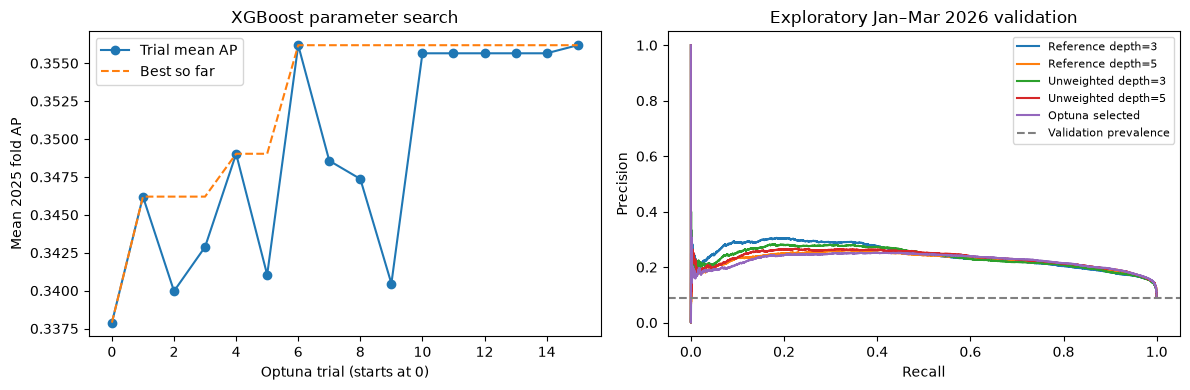

Saved separate research outputs: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/08_xgboost/20261027_163044_632630
Original models, dashboard and active-run selection were not replaced.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ordered = trial_summary.sort_values("trial")
axes[0].plot(ordered.trial, ordered.mean_ap, "o-", label="Trial mean AP")
axes[0].plot(ordered.trial, ordered.mean_ap.cummax(), "--", label="Best so far")
axes[0].set(xlabel="Optuna trial (starts at 0)", ylabel="Mean 2025 fold AP", title="XGBoost parameter search")
axes[0].legend()
for label, scores in validation_scores.items():
    p, r, _ = precision_recall_curve(validation.surge_label, scores)
    axes[1].plot(r, p, label=label)
axes[1].axhline(validation.surge_label.mean(), color="grey", linestyle="--", label="Validation prevalence")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Exploratory Jan–Mar 2026 validation")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

# Recheck exact inputs before publishing this separate result folder.
if any(file_hash(cfg.PROJECT_ROOT / name) != digest for name, digest in input_hashes.items()):
    raise ValueError("Prepared inputs changed during tuning. No completed result is published.")
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
OUTPUT_DIR = cfg.PROJECT_ROOT / "08_xgboost" / stamp
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
for filename, table in {
    "trial_fold_metrics.csv": trial_folds, "trial_summary.csv": trial_summary,
    "fold_comparison.csv": fold_comparison, "fold_summary.csv": fold_summary.reset_index(),
    "validation_comparison.csv": validation_comparison, "validation_group_metrics.csv": group_comparison,
}.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)
study.trials_dataframe().to_csv(OUTPUT_DIR / "optuna_trials.csv", index=False)
fig.savefig(OUTPUT_DIR / "tuning_and_validation.png", dpi=160, bbox_inches="tight")
predictions = validation[["item_code", "state", "district", "premise_type", "project_group",
                          "week_start", "next_week_end", "surge_label"]].copy()
predictions["model_score"] = selected_scores
predictions["alert_at_05"] = selected_scores >= 0.5
predictions["alert_at_selected_cutoff"] = selected_scores >= selected_cutoff
predictions.to_parquet(OUTPUT_DIR / "validation_predictions.parquet", index=False)
joblib.dump(selected_pipeline, OUTPUT_DIR / "xgboost.joblib")
selection = {"family": "XGBoost", "parameters": BEST_PARAMETERS,
             "fixed_parameters": {"n_estimators": TREES, "learning_rate": 0.05, "subsample": 0.8,
                                  "colsample_bytree": 0.8, "tree_method": "hist",
                                  "objective": "binary:logistic", "eval_metric": "logloss"},
             "training_scale_pos_weight": selected_pipeline.named_steps["model"].get_params()["scale_pos_weight"],
             "seed": SEED, "n_jobs": N_JOBS, "trials": N_TRIALS,
             "search": SEARCH_SPACE,
             "reference_settings": [{"method": label, "parameters": parameters}
                                    for label, parameters in REFERENCE_SETTINGS],
             "selection_metric": "mean AP over three expanding 2025 folds; earliest trial breaks ties",
             "selected_trial": best_trial.number, "score_cutoff": selected_cutoff,
             "cutoff_rule": "maximum Jan–Mar validation F1; highest cutoff breaks ties",
             "feature_columns": FEATURES, "surge_threshold_pct": 10.0,
             "training_end": settings["train_end"], "validation_end": settings["validation_end"],
             "refit_on_validation": False, "score_interpretation": "uncalibrated model score"}
(OUTPUT_DIR / "selection.json").write_text(json.dumps(selection, indent=2))
versions = {p: metadata.version(p) for p in ["optuna", "pandas", "numpy", "scikit-learn", "joblib"]}
versions["xgboost_module"] = xgb.__version__
for distribution in ["xgboost", "xgboost-cpu"]:
    try:
        versions[distribution] = metadata.version(distribution)
    except metadata.PackageNotFoundError:
        pass  # The platform-specific requirement installs one of these distributions.
manifest = {"status": "completed", "study_status": "supplementary exploratory tuning; test not accessed",
            "input_sha256": input_hashes, "selection": selection,
            "preparation": {name: s["preparation"] for name, s in settings_by_fold.items()},
            "package_versions": versions,
            "notebook_sha256": file_hash(REPOSITORY_ROOT / "08_xgboost.ipynb"),
            "output_sha256": {p.name: file_hash(p) for p in OUTPUT_DIR.iterdir() if p.is_file()}}
(OUTPUT_DIR / "study_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved separate research outputs:", OUTPUT_DIR)
print("Original models, dashboard and active-run selection were not replaced.")

## 7. Implementation and results notes for the report

**Evidence snapshot:** these notes describe the saved local execution reviewed on **27 October 2026**. They are explanatory Markdown, not new calculations. If a later reproduction changes the outputs, update these historical notes before quoting them as current results. Model selection, code and saved outputs were not changed by adding this explanation.

### 7.1 How XGBoost was implemented

XGBoost builds an additive sequence of trees. A schematic binary-classification score is:

$$F_M(x)=b+\eta\sum_{m=1}^{M}f_m(x),\qquad s(x)=\sigma(F_M(x)),$$

where $b$ is an initial margin, $f_m$ is a tree contribution, $M=150$, $\eta=0.05$ and $\sigma$ is the sigmoid. Each new tree improves the current training objective using gradient information. Histogram-based split finding is used here.

Depth restricts complexity. `min_child_weight` controls minimum summed Hessian support, not an exact row count. `reg_lambda` regularises leaf weights. The notebook's `weighting` option maps to `scale_pos_weight=1` or training negatives divided by training positives; it is not itself an XGBoost constructor parameter. The ratio is recomputed inside each fit without validation labels. Preprocessing is training-fitted, with imputation and one-hot encoding but no scaling. Section 1 states the search ranges and fixed sampling settings.

All 16 trials are sequential proposals from seeded Optuna TPE. Each proposal is fitted independently on the three expanding 2025 folds, including a fresh preprocessor. The objective is mean fold AP, not accuracy or F1. Four queued references include the original two weighted settings and their unweighted counterparts. A trial is an evaluation attempt, not necessarily a unique configuration; the saved search contains repeated proposals. Keep the actual trial history rather than claiming 16 distinct configurations.

### 7.2 Selected configuration

| Parameter | Selected value |
|---|---|
| `max_depth` | 7 |
| `min_child_weight` | 1 |
| `reg_lambda` | 10.0 |
| `weighting` | none |

The selected setting maximised the declared mean-fold AP objective. Its score cutoff was chosen separately on January–March 2026 validation; changing this cutoff does not alter the 10% price-rise definition.

### 7.3 Evidence of predictive performance

| Method | Mean 2025 fold AP | Fold AP standard deviation | Jan–Mar 2026 validation AP |
|---|---:|---:|---:|
| Always no surge | 0.1061 | 0.0106 | 0.0897 |
| Current-change rule | 0.1210 | 0.0268 | 0.1016 |
| Reference depth=3 | 0.3379 | 0.0438 | 0.2423 |
| Reference depth=5 | 0.3462 | 0.0588 | 0.2259 |
| Optuna selected | 0.3562 | 0.0606 | 0.2249 |

The constant no-surge score has AP equal to prevalence when both classes are present; this does not mean it detects surges. Its precision/recall/F1 under the no-alert rule are zero here. AP is sklearn average precision, not trapezoidal PR-AUC. Fold standard deviation describes temporal variation, not a confidence interval or significance test.

**Interpretation:** Mean fold AP increased from 0.3462 for the original depth-5 reference to 0.3562. Later validation AP was 0.2249, below both original references (0.2423 at depth 3 and 0.2259 at depth 5). Thus the search-period gain did not demonstrate a consistent later-period improvement. Higher validation recall at the selected cutoff required many alerts; it is not evidence of uniformly better prediction.

### 7.4 What the alert cutoff changes

Both rows below use the same selected fitted model and the same **43,594 validation rows**, containing **3,912 surges**. AP is unchanged by moving the cutoff.

| Operating point | Cutoff | Precision | Recall | F1 | Alerts | Correct alerts | False alerts | Missed surges |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Common reference | 0.5000 | 23.0% | 13.8% | 0.1721 | 2,342 | 538 | 1,804 | 3,374 |
| Validation-selected | 0.1407 | 22.7% | 73.3% | 0.3466 | 12,642 | 2,869 | 9,773 | 1,043 |

The selected cutoff maximises F1 on this same validation period, with the highest cutoff breaking ties. These are **apparent cutoff-selection metrics**, not independent test estimates. 77.3% of selected-cutoff alerts were false. The score is uncalibrated; the cutoff is not a verified event probability or a percentage price increase.

### 7.5 Food groups and limitations

Vegetables contribute 2,837 of 2,869 correct alerts. Chicken recall is 44.0% (11/25); eggs 24.5% (13/53); flour 46.7% (7/15). Cooking oil has just one positive and rice two. Sugar has no observed surges and received one false alert, so positive-case detection for sugar remains unevaluable.

Overall metrics therefore need group support and recall alongside them. SHAP contributions do not establish economic causes, and this experiment does not demonstrate affordability or stakeholder-adoption benefits. The data were prepared using the existing documented source/coverage rules, so unresolved source quality and changing observation composition remain limitations.

### 7.6 How to explain the result in your report

**Implementation chapter:** describe the technique above, training-fitted preprocessing, parameter ranges in section 1, fixed settings, class-weight policy, 16-trial search, chronological folds and AP objective. Cite appropriate methodological references for the algorithm and Optuna; this notebook is implementation evidence, not a substitute for those references.

**Results chapter:** use section 7.3 for reference-versus-tuned ranking, section 7.4 for the alert trade-off, and the displayed group table for support and uneven performance. Explain both gains and weaknesses; do not report only the largest score. A fitting-time field includes fitting and scoring, not just estimator training.

**Conclusion:** The selected setting improved fold ranking but not later validation ranking. Its selected cutoff detected more surges than the other tuned candidates by issuing more alerts; this does not establish a universally better operating policy. Retaining or replacing a dashboard checkpoint is a separate operational decision; this exploratory study does not automatically replace it.

**Evidence files:** `trial_summary.csv` and `optuna_trials.csv` record the search; `trial_fold_metrics.csv` and `fold_comparison.csv` contain per-fold evidence; `fold_summary.csv` aggregates folds; `validation_comparison.csv` and `validation_group_metrics.csv` support later-period discussion. `selection.json` records parameters/cutoff and `study_manifest.json` records exact inputs, package versions and output hashes. Use those hashes to establish matching datasets across models; equal dates and row counts alone are insufficient.

The original April–June 2026 test has been inspected and is not evaluated here. Neither these validation figures nor another model's original test scores establish this candidate's independent test performance. Further final claims need a genuinely untouched period and a frozen protocol. Do not retune or change the selection because these later results are visible.
